# Sesión 03 — Regresión lineal simple y múltiple

**Bloque:** 2 · Regresión

## Objetivos

Al terminar esta sesión deberías ser capaz de:

- Decidir si un problema se ataca con una sola variable o con varias, y justificar la decisión con datos y no con intuición.
- Preparar un dataset con variables categóricas para un modelo lineal, eligiendo la codificación y explicando qué hace `drop_first`.
- Entrenar y evaluar una `LinearRegression` sobre datos que el modelo no ha visto, leyendo R², MAE y RMSE juntos y no por separado.
- Traducir los coeficientes del modelo a frases que un cliente entienda ("cada año de edad suma X € a la prima").
- Comparar dos modelos con distinto número de variables y defender cuál de los dos entregarías.

## Qué necesitas de antes

- **S02 — Python aplicado al análisis de datos**: pandas, lectura de ficheros desde URL, gráficos con seaborn y matplotlib.
- Selección de columnas en un DataFrame y lectura de un `describe()`.


## 1. ¿Qué es la Regresión?

En Machine Learning, usamos la regresión cuando queremos predecir un valor **numérico continuo**. Por ejemplo:
- Predecir el precio de una casa.
- Estimar la temperatura de mañana.
- Predecir el coste del seguro médico de una persona (¡nuestro caso de hoy!).

La **Regresión Lineal** es el modelo más sencillo para esta tarea. Asume que existe una relación lineal entre las variables de entrada (X, también llamadas *features* o predictoras) y la variable de salida (y, también llamada *target* o variable dependiente). La fórmula que busca aprender es la de una línea (o un hiperplano en más dimensiones):

$y = \beta_0 + \beta_1x_1 + \beta_2x_2 + ... + \beta_nx_n$

- $\beta_0$ es el **intercepto** (el valor de $y$ cuando todas las $x$ son cero).
- $\beta_1, \beta_2, ...$ son los **coeficientes** de cada variable. Nos dicen cuánto cambia $y$ por cada unidad que aumenta la $x$ correspondiente, manteniendo las demás constantes.

- **Regresión Lineal Simple:** Solo tenemos una variable de entrada ($x_1$).
- **Regresión Lineal Múltiple:** Usamos varias variables de entrada ($x_1, x_2, ..., x_n$).

**Qué problema resuelve:** predecir un número continuo a partir de otras variables, cuando además interesa poder *explicar* la predicción.

**Cuándo elegirla:** como primer modelo casi siempre. Es rápida, no tiene hiperparámetros que ajustar y sus coeficientes se leen directamente en unidades del negocio. Es la referencia contra la que se compara todo lo demás: si un modelo más complejo no la supera, no compensa.

**Cuándo NO:** cuando la relación es claramente curva o hay interacciones fuertes entre variables (un efecto que solo aparece al combinar dos), o cuando hay muchas más columnas que filas.

**Qué asume:** que la relación entre cada variable y el objetivo es lineal, que los errores no dependen del tamaño de la predicción y que las variables predictoras no son redundantes entre sí. Los tres supuestos se incumplen a menudo, y parte del trabajo de hoy es detectar dónde.


In [1]:
# Importamos las librerías fundamentales que usaremos en la sesión
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Configuramos seaborn para que los gráficos se vean un poco más atractivos
sns.set_theme(style="whitegrid")

## 2. Carga y Exploración de Datos (EDA)

Vamos a trabajar con el dataset "Medical Cost Personal Datasets", que se encuentra en Kaggle. Contiene información anónima sobre los asegurados de una compañía y su objetivo es predecir los `charges` (costes médicos facturados).

Las columnas son:
- `age`: edad del beneficiario.
- `sex`: sexo del beneficiario.
- `bmi`: índice de masa corporal.
- `children`: número de hijos cubiertos por el seguro.
- `smoker`: si la persona es fumadora o no.
- `region`: la región de residencia en EEUU.
- `charges`: los costes médicos individuales facturados por el seguro (nuestra **variable objetivo**).

In [3]:
# Cargamos los datos directamente desde una URL para que sea reproducible
url = 'https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv'
df = pd.read_csv(url)

In [4]:
# Damos un primer vistazo a los datos
print("Primeras 5 filas del dataset:")
print(df.head())

Primeras 5 filas del dataset:
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520


In [5]:
print("\nInformación general y tipos de datos:")
df.info()


Información general y tipos de datos:
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


In [6]:
print("\nEstadísticas descriptivas de las columnas numéricas:")
print(df.describe())


Estadísticas descriptivas de las columnas numéricas:
               age          bmi     children       charges
count  1338.000000  1338.000000  1338.000000   1338.000000
mean     39.207025    30.663397     1.094918  13270.422265
std      14.049960     6.098187     1.205493  12110.011237
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.296250     0.000000   4740.287150
50%      39.000000    30.400000     1.000000   9382.033000
75%      51.000000    34.693750     2.000000  16639.912515
max      64.000000    53.130000     5.000000  63770.428010


### Análisis Visual

Antes de construir un modelo, un buen analista siempre "mira" sus datos. Las visualizaciones nos dan una intuición clave.

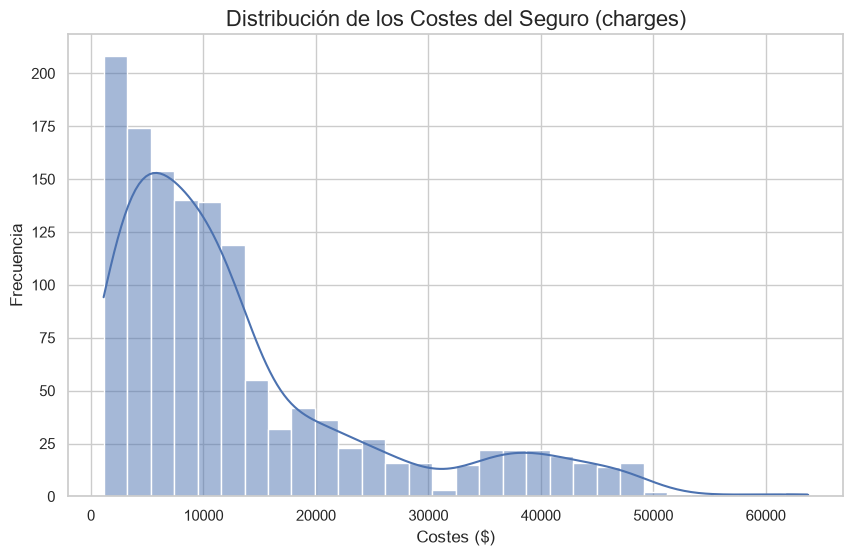

In [7]:
# 1. ¿Cómo se distribuyen los costes (nuestra variable objetivo)?
plt.figure(figsize=(10, 6))
sns.histplot(df['charges'], kde=True)
plt.title('Distribución de los Costes del Seguro (charges)', fontsize=16)
plt.xlabel('Costes ($)')
plt.ylabel('Frecuencia')
plt.show()

# Reflexión: Vemos que la mayoría de la gente tiene costes bajos, con una larga cola hacia la derecha (right-skewed).
# Esto nos dice que hay un grupo de personas con costes muy, muy altos. ¿Quiénes serán?

## 3. Preparación de Datos

Los modelos de machine learning no entienden de texto ('male', 'female', 'yes', 'no'). Necesitamos convertir las variables categóricas en números. La técnica estándar es **One-Hot Encoding**. `pandas` nos lo pone muy fácil con la función `get_dummies`.

In [9]:
# Convertimos las variables categóricas en numéricas
df_encoded = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first=True)

# drop_first=True evita la multicolinealidad. Por ejemplo, si tenemos sex_male, no necesitamos
# una columna sex_female, porque si sex_male es 0, sabemos que es female.

print("Dataset después de One-Hot Encoding:")
print(df_encoded.head())

Dataset después de One-Hot Encoding:
   age     bmi  children      charges  sex_male  smoker_yes  region_northwest  \
0   19  27.900         0  16884.92400     False        True             False   
1   18  33.770         1   1725.55230      True       False             False   
2   28  33.000         3   4449.46200      True       False             False   
3   33  22.705         0  21984.47061      True       False              True   
4   32  28.880         0   3866.85520      True       False              True   

   region_southeast  region_southwest  
0             False              True  
1              True             False  
2              True             False  
3             False             False  
4             False             False  


### Matriz de Correlación

Ahora que todo es numérico, podemos calcular la correlación entre todas las variables. Una matriz de correlación visualizada con un mapa de calor (heatmap) es una herramienta potentísima para intuir qué variables serán más importantes para predecir `charges`.

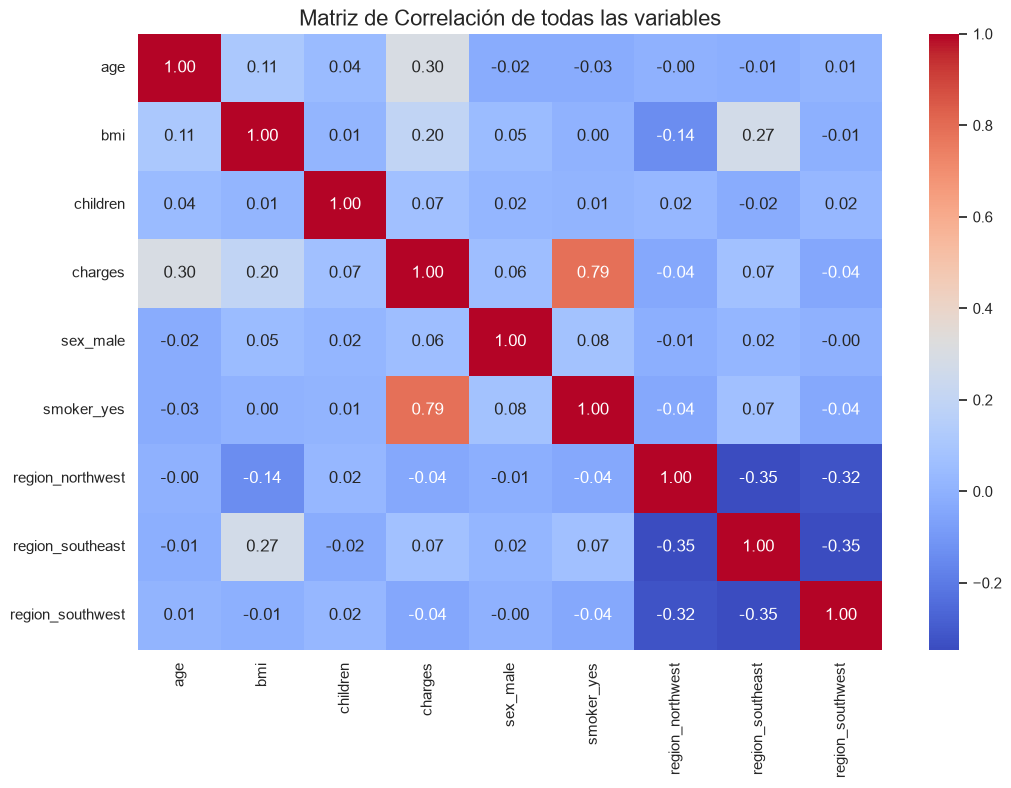

In [10]:
plt.figure(figsize=(12, 8))
sns.heatmap(df_encoded.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriz de Correlación de todas las variables', fontsize=16)
plt.show()

# Interpretación: Buscamos en la fila/columna 'charges' los colores más intensos (rojos o azules).
# 'smoker_yes' tiene una correlación muy alta (0.79), 'age' (0.30) y 'bmi' (0.20) también parecen relevantes.
# ¡Esto ya nos da pistas para nuestro modelo!

## 4. Modelo de Regresión Lineal Múltiple (Ejemplo Guiado)

Vamos a construir nuestro primer modelo para predecir `charges` usando todas las variables disponibles.

**Pasos clave:**
1.  **Separar X e y**: `X` contiene las variables predictoras, `y` contiene la variable objetivo.
2.  **Dividir en train/test**: Usamos una parte de los datos para entrenar el modelo (`train`) y una parte que el modelo no ha visto nunca para evaluarlo (`test`). Esto es CRUCIAL para saber si nuestro modelo generaliza bien.

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# 1. Separar las variables predictoras (X) de la variable objetivo (y)
X = df_encoded.drop('charges', axis=1)
y = df_encoded['charges']

# 2. Dividir los datos en entrenamiento y prueba
# Usamos un 80% para entrenar y un 20% para testear.
# random_state=42 asegura que la división sea siempre la misma, para que nuestros resultados sean reproducibles.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Crear y entrenar el modelo
# Creamos una instancia del modelo de Regresión Lineal
model = LinearRegression()

# Entrenamos el modelo con los datos de entrenamiento
model.fit(X_train, y_train)

print("¡Modelo entrenado con éxito!")

¡Modelo entrenado con éxito!


## 5. ¿Qué tan bueno es nuestro modelo? Evaluación

Entrenar un modelo es fácil. La parte difícil es saber si es bueno. Para ello, usamos los datos de `test` que habíamos guardado.

**Hacemos predicciones y las comparamos con la realidad.**

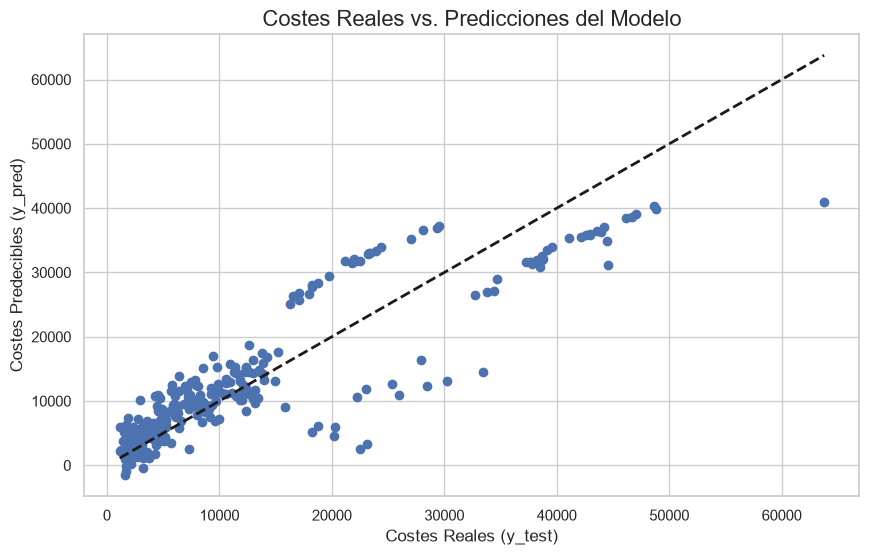

In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Hacemos predicciones sobre el conjunto de test (datos que el modelo no ha visto)
y_pred = model.predict(X_test)

# Visualicemos qué tan cerca están las predicciones de la realidad
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred)
plt.xlabel("Costes Reales (y_test)")
plt.ylabel("Costes Predecibles (y_pred)")
plt.title("Costes Reales vs. Predicciones del Modelo", fontsize=16)
# Dibujamos una línea de 45 grados. Si las predicciones fueran perfectas, todos los puntos caerían sobre esta línea.
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.show()

### Métricas de Error

- **MAE (Error Absoluto Medio):** Nos dice, en promedio, cuántos dólares se equivoca nuestra predicción. Es fácil de interpretar.
- **RMSE (Raíz del Error Cuadrático Medio):** Similar al MAE, pero como eleva los errores al cuadrado, penaliza mucho más los errores grandes.
- **$R^2$ (R-cuadrado):** Nos dice qué porcentaje de la variación de los costes es explicado por el modelo. Va de 0 a 1 (o incluso negativo). Un valor más cercano a 1 es mejor.

In [13]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE (Error Absoluto Medio): ${mae:,.2f}")
print(f"RMSE (Raíz del Error Cuadrático Medio): ${rmse:,.2f}")
print(f"R-cuadrado (R²): {r2:.2f}")

MAE (Error Absoluto Medio): $4,181.19
RMSE (Raíz del Error Cuadrático Medio): $5,796.28
R-cuadrado (R²): 0.78


### Interpretación de Coeficientes
¿Qué ha aprendido el modelo? ¿Qué variables considera más importantes?

In [14]:
# Creamos un DataFrame para ver los coeficientes de forma ordenada
coeficientes = pd.DataFrame(model.coef_, X.columns, columns=['Coeficiente'])
print("Intercepto del modelo (Beta_0):", model.intercept_)
print("\nCoeficientes de las variables:")
print(coeficientes)

# Interpretación: Por cada año que una persona envejece ('age'), el coste de su seguro aumenta en ~$256, si todo lo demás se mantiene constante.
# ¡Ser fumador ('smoker_yes') dispara los costes en casi $24,000!

Intercepto del modelo (Beta_0): -11931.219050326692

Coeficientes de las variables:
                   Coeficiente
age                 256.975706
bmi                 337.092552
children            425.278784
sex_male            -18.591692
smoker_yes        23651.128856
region_northwest   -370.677326
region_southeast   -657.864297
region_southwest   -809.799354


---
## Ejercicio 1 — Regresión lineal simple

Ahora es tu turno. La intuición y la matriz de correlación nos dijeron que `bmi` (Índice de Masa Corporal) podría ser un predictor. Vamos a investigarlo por sí solo.

**Tareas:**
1.  **Define tus variables `X_simple` e `y_simple`**. `X_simple` debe ser únicamente la columna `bmi` del dataframe `df_encoded`. `y_simple` sigue siendo `charges`.
2.  **Divide los datos** en conjuntos de entrenamiento y prueba (`train_test_split`). Usa un `test_size=0.2` y `random_state=42`.
3.  **Crea y entrena un nuevo modelo** de `LinearRegression`.
4.  **Realiza predicciones** sobre el conjunto de prueba.
5.  **Calcula el R-cuadrado ($R^2$)** del modelo. ¿Qué tan bueno es comparado con el modelo múltiple que hicimos antes?
6.  **Visualiza el resultado**: Dibuja un `scatterplot` con los datos de prueba (`X_test_simple`, `y_test_simple`) y superpón la línea de regresión que ha aprendido tu modelo.

MAE (Error Absoluto Medio): $9,784.65
RMSE (Raíz del Error Cuadrático Medio): $12,210.04
R-cuadrado (R²): 0.04


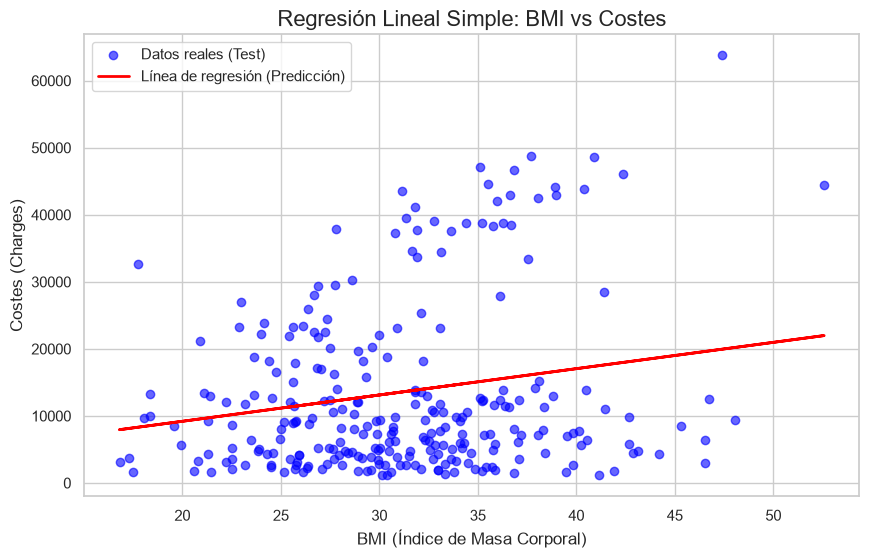

In [15]:
# ==============================================================================
# PASO 1: DEFINIR LAS VARIABLES INDEPENDIENTE (X) Y DEPENDIENTE (y)
# ==============================================================================
# Usamos dobles corchetes [["bmi"]] para extraer un DataFrame de 2 dimensiones (2D).
# Scikit-learn requiere obligatoriamente que X sea 2D, a diferencia de y que es 1D (Series).
X_simple = df_encoded[["bmi"]]

# Definimos la variable objetivo 'y' (costes médicos que queremos predecir)
y_simple = df_encoded["charges"]


# ==============================================================================
# PASO 2: DIVIDIR LOS DATOS EN CONJUNTOS DE ENTRENAMIENTO Y PRUEBA
# ==============================================================================
# train_test_split devuelve exactamente 4 elementos en este orden:
# X_train (características entrenamiento), X_test (características prueba),
# y_train (objetivo entrenamiento), y_test (objetivo prueba).
# test_size=0.2 reserva el 20% para pruebas y random_state=42 asegura reproducibilidad.
X_train, X_test, y_train, y_test = train_test_split(
    X_simple, y_simple, test_size=0.2, random_state=42 # random_state: la aleatoriedad siempre empieza desde una misma parte y tenemos todos los mismos resultados.
)


# ==============================================================================
# PASO 3: CREAR Y ENTRENAR EL MODELO DE REGRESIÓN LINEAL
# ==============================================================================
# Instanciamos la clase de Regresión Lineal en la variable 'new_model'
new_model = LinearRegression()

# Entrenamos (ajustamos) el modelo únicamente usando los datos de entrenamiento
new_model.fit(X_train, y_train)


# ==============================================================================
# PASO 4: REALIZAR PREDICCIONES
# ==============================================================================
# Le pasamos al modelo entrenado los datos no vistos (X_test) para predecir 'y'
y_pred = new_model.predict(X_test)


# ==============================================================================
# PASO 5: EVALUAR EL RENDIMIENTO DEL MODELO (MÉTRICAS)
# ==============================================================================
# Calculamos el Error Absoluto Medio (diferencia promedio en dólares entre real y predicho)
mae = mean_absolute_error(y_test, y_pred)

# Calculamos el Error Cuadrático Medio
mse = mean_squared_error(y_test, y_pred)

# Calculamos la Raíz del Error Cuadrático Medio (en las mismas unidades que la variable 'y')
rmse = np.sqrt(mse)

# Calculamos el coeficiente de determinación R² (porcentaje de varianza explicada)
r2 = r2_score(y_test, y_pred) # Cuanto más cerca a 1 mejor el resultado comparado con el test y la predicción

# Imprimimos las métricas formateadas a 2 decimales y con separador de miles
print(f"MAE (Error Absoluto Medio): ${mae:,.2f}")
print(f"RMSE (Raíz del Error Cuadrático Medio): ${rmse:,.2f}")
print(f"R-cuadrado (R²): {r2:.2f}")


# ==============================================================================
# PASO 6: VISUALIZAR LOS RESULTADOS
# ==============================================================================
# Configuramos el tamaño de la figura en pulgadas (ancho, alto)
plt.figure(figsize=(10, 6))

# Dibujamos los puntos reales de datos del conjunto de prueba (scatterplot)
plt.scatter(
    X_test, y_test, color="blue", label="Datos reales (Test)", alpha=0.6
)

# Dibujamos la recta de regresión ajustada aprendida por el modelo
plt.plot(
    X_test,
    y_pred,
    color="red",
    linewidth=2,
    label="Línea de regresión (Predicción)",
)

# Añadimos etiquetas, título y leyenda para identificar los componentes
plt.xlabel("BMI (Índice de Masa Corporal)")
plt.ylabel("Costes (Charges)")
plt.title("Regresión Lineal Simple: BMI vs Costes", fontsize=16)
plt.legend()

# Mostramos el gráfico final
plt.show()

### Mis reflexiones

*(Escribe aquí tu respuesta antes de seguir)*

- Acabas de ver que `bmi` por sí solo explica muy poco del gasto. ¿Qué conclusión sacas: que la variable no sirve, o que el problema es otro? Argumenta cuál de las dos.

    - Que el problema es otro, porque puede depender de otros factores. Y si tienen sobrepeso, o fuman...Nos faltarian más variables

- En el gráfico hay puntos que quedan muy por encima de la recta. Sin mirar todavía el resto de columnas, ¿qué hipótesis te haces sobre esas personas y cómo la comprobarías?

    - Que pueden ser personas que fuman. Tienen algo en común. Y se podria comprobar añadiendo otra dimensión poniendo colores a los puntos para saber si son fumadores o no

- Si la aseguradora te pidiera hoy una estimación rápida del coste de un cliente nuevo y solo tuvieras este modelo, ¿la darías? ¿Con qué advertencia?

    - No, porque se necesitaria más información y rehacerlo

---
## Preguntas de recap – Regresión simple

1. ¿Qué mide el coeficiente de una regresión lineal simple?

        Mide el cambio esperado en la variable dependiente (Y) por cada aumento de una unidad en la variable independiente (X). En términos gráficos, representa la inclinación o pendiente de la línea de regresión.

2. ¿Qué significa el intercepto (ordenada en el origen)?

        Representa el valor estimado de la variable dependiente (Y) cuando la variable independiente (X) es exactamente igual a cero. Es decir, es el punto donde la línea de ajuste cruza el eje vertical (eje Y).

3. ¿Qué nos indica el R² de un modelo?

        También llamado "coeficiente de determinación", indica la proporción (o porcentaje) de la varianza de la variable dependiente que es explicada por nuestro modelo (por la variable independiente). Un R² más cercano a 1 (o 100%) indica que el modelo se ajusta muy bien a los datos observados.

4. Si al ajustar una regresión obtenemos un coeficiente negativo, ¿cómo lo interpretarías?

        Significa que existe una relación inversa (o negativa) entre las variables. Es decir, a medida que la variable independiente (X) aumenta, la variable dependiente (Y) tiende a disminuir.

---


---
## Ejercicio 2 — Un modelo más simple

El modelo con todas las variables es mucho mejor que el que solo usa `bmi`. Pero en el mundo real, la simplicidad es una virtud. Un modelo con menos variables es más fácil de explicar y mantener.

**Tu misión:**
Construye y evalúa un modelo de regresión lineal múltiple usando **únicamente un subconjunto de variables** que, a tu juicio (y según el heatmap), son las más importantes: `age`, `bmi` y `smoker_yes`.

**Pasos:**
1.  Prepara tu `X_reducido` seleccionando solo esas tres columnas del dataframe `df_encoded`. La `y` no cambia.
2.  Divide los datos en entrenamiento y prueba (`random_state=42`).
3.  Entrena el modelo de regresión lineal.
4.  Realiza una **evaluación completa**: calcula el MAE, RMSE y $R^2$.
5.  Crea la **visualización** de predicciones vs. valores reales para este nuevo modelo.

**--- Preguntas para la Reflexión ---**

**Responde a estas preguntas en una celda de texto (Markdown) al final de tu notebook:**

1.  **Comparación de Modelos:** Compara el $R^2$ y el MAE de este modelo reducido con el del modelo que usaba *todas* las variables. ¿Cuánta precisión (en dólares de error promedio) hemos "sacrificado" a cambio de un modelo más simple?
2.  **Decisión de Negocio:** Imagina que tienes que presentarle uno de los dos modelos (el completo vs. el reducido) a tu manager. ¿Cuál elegirías y por qué? Justifica tu respuesta pensando en el equilibrio entre rendimiento, simplicidad y explicabilidad.
3.  **Análisis Crítico:** Viendo el gráfico de predicciones vs. realidad de tu modelo reducido, ¿en qué zona parece fallar más? ¿Predice bien los costes muy altos o los muy bajos? ¿Por qué crees que ocurre esto, basándote en las variables que has usado?

MAE (Error Absoluto Medio): $4,260.56
RMSE (Raíz del Error Cuadrático Medio): $5,874.76
R-cuadrado (R²): 0.78


C:\Users\User\AppData\Local\Temp\ipykernel_15712\2238469357.py:42: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k--" (-> color='k'). The keyword argument will take precedence.
  plt.plot(


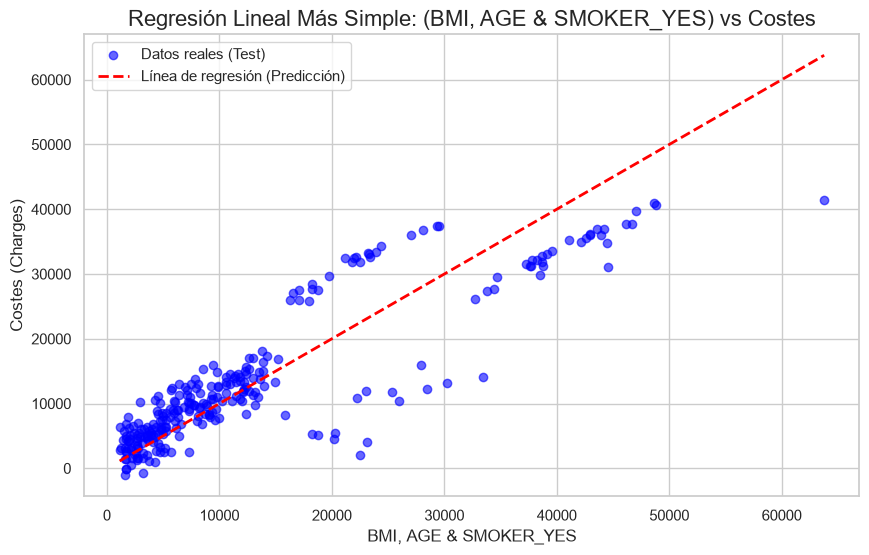

In [16]:

# TODO: completa esta celda
# Las tres columnas ya existen en df_encoded: no hay que volver a codificar nada.
# Manten el mismo random_state y test_size que el modelo completo, o la comparacion de metricas no sera justa.

# 1. Prepara tu X_reducido
X_reducido = df_encoded[["age", "bmi", "smoker_yes"]]
y_simple = df_encoded["charges"]

# 2. Divide los datos de entrenamiento y comprueba con random_state=42
X_train, X_test, y_train, y_test = train_test_split(X_reducido, y_simple, random_state=42, test_size=0.2)

# 3. Entrenar modelo de regresión lineal (Pasamos 80% del modelo, entrenando el modelo lineal)
new_model = LinearRegression()
new_model.fit(X_train, y_train)


# 4. Evaluación completa
# y_test es lo que vale charges para X_test | y_pred es la estimación que hace el modelo según un valor futuro
y_pred = new_model.predict(X_test) # Le metemos las variables de X_test y nos da de salida la predición del modelo (cual será charges en ese caso)
mae = mean_absolute_error(y_test, y_pred) # MAE (Comparo la diferencia que hay entre los charges que habia y los que ha predicido el modelo)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse) # RMSE
r2 = r2_score(y_test, y_pred) # R^2

print(f"MAE (Error Absoluto Medio): ${mae:,.2f}")
print(f"RMSE (Raíz del Error Cuadrático Medio): ${rmse:,.2f}")
print(f"R-cuadrado (R²): {r2:.2f}")


# 5. Crea la visualización
plt.figure(figsize=(10, 6))

plt.scatter(
    y_test, y_pred, color="blue", label="Datos reales (Test)", alpha=0.6
)

#print(f"Y_test {y_test}")
#print(y_test.min())
#print(y_test.min(), y_test.max())
#print(y_test.min(), y_test.max())

plt.plot(
    [y_test.min(), y_test.max()], # Array de Xs
    [y_test.min(), y_test.max()], # Array de Ys
    'k--',
    color="red",
    linewidth=2,
    label="Línea de regresión (Predicción)",
)

plt.xlabel("BMI, AGE & SMOKER_YES")
plt.ylabel("Costes (Charges)")
plt.title("Regresión Lineal Más Simple: (BMI, AGE & SMOKER_YES) vs Costes", fontsize=16)
plt.legend()

# Mostramos el gráfico final
plt.show()

1.  Comparación de Modelos: Compara el $R^2$ y el MAE de este modelo reducido con el del modelo que usaba todas las variables. ¿Cuánta precisión (en dólares de error promedio) hemos "sacrificado" a cambio de un modelo más simple?

       - Más o menos del MAE hay una diferencia de 100. De R^2 alrededor de 0.01 tan poco que nos va mejor utilizar el reducido ya que no se dispersa tanto el error.

2.  Decisión de Negocio: Imagina que tienes que presentarle uno de los dos modelos (el completo vs. el reducido) a tu manager. ¿Cuál elegirías y por qué? Justifica tu respuesta pensando en el equilibrio entre rendimiento, simplicidad y explicabilidad.
      
       - Escogeria el reducido porque es completamente igual al otro pero mucho más facil de explicar.

3.  Análisis Crítico: Viendo el gráfico de predicciones vs. realidad de tu modelo reducido, ¿en qué zona parece fallar más? ¿Predice bien los costes muy altos o los muy bajos? ¿Por qué crees que ocurre esto, basándote en las variables que has usado?
       
       - La influencia que tienen BMI, ser fumador o incluso age no se suma. El efecto que hacen nuestras variables no el lineal.

### Mis Reflexiones

*(Escribe aquí tus respuestas a las preguntas)*

---
## Preguntas de recap – Regresión múltiple

1. ¿Cómo interpretas el coeficiente de una variable en una regresión múltiple?  

    - Representa el cambio esperado en la variable objetivo (target) por cada unidad de aumento en esa variable predictora, asumiendo que todas las demás variables del modelo se mantienen constantes (el efecto aislado de esa variable).

    - Cuanto peso aporta, si tiene mucho peso afecta más sino menos. Y según si es positivo o negativo son los 
 
2. ¿Por qué puede cambiar el valor de un coeficiente cuando añadimos nuevas variables al modelo?  

    - Porque las variables predictoras suelen estar correlacionadas entre sí (multicolinealidad). Al añadir nuevas variables, el modelo reajusta los pesos para tener en cuenta la información compartida o superpuesta entre ellas. El coeficiente pasa a reflejar solo su aporte de información única.

3. ¿Qué significa que un modelo esté sobreajustado (overfitting)?  

    - Significa que el modelo es tan complejo que ha "memorizado" los datos de entrenamiento (incluyendo su ruido y anomalías) en lugar de aprender el patrón general subyacente. El síntoma clásico es un rendimiento excelente en entrenamiento, pero predicciones desastrosas al enfrentarse a datos nuevos (test).

4. ¿Qué ventajas tiene evaluar un modelo con métricas como MAE, RMSE además de R²?

    - Mientras que el R² te da una proporción abstracta (de 0 a 1) sobre cuánta varianza explica el modelo, el MAE y el RMSE te muestran el margen de error en las mismas unidades que la variable original (euros, kg, edades). Esto es indispensable para saber si el error en la predicción es aceptable para resolver tu problema real.

---


---
## Ejercicio 3 — Otro dataset (opcional)

1. Carga un dataset distinto (por ejemplo, `sklearn.datasets.load_diabetes()` o uno que elijas tú).  
2. Ajusta una regresión múltiple con al menos 3 variables predictoras.  
3. Evalúa el modelo usando R² y RMSE.  
4. Interpreta qué variable parece tener más influencia en la predicción.  

Si quieres ir más allá: prueba a estandarizar las variables y compara los coeficientes.
---


HEAD:
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  
INFO:
<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   b

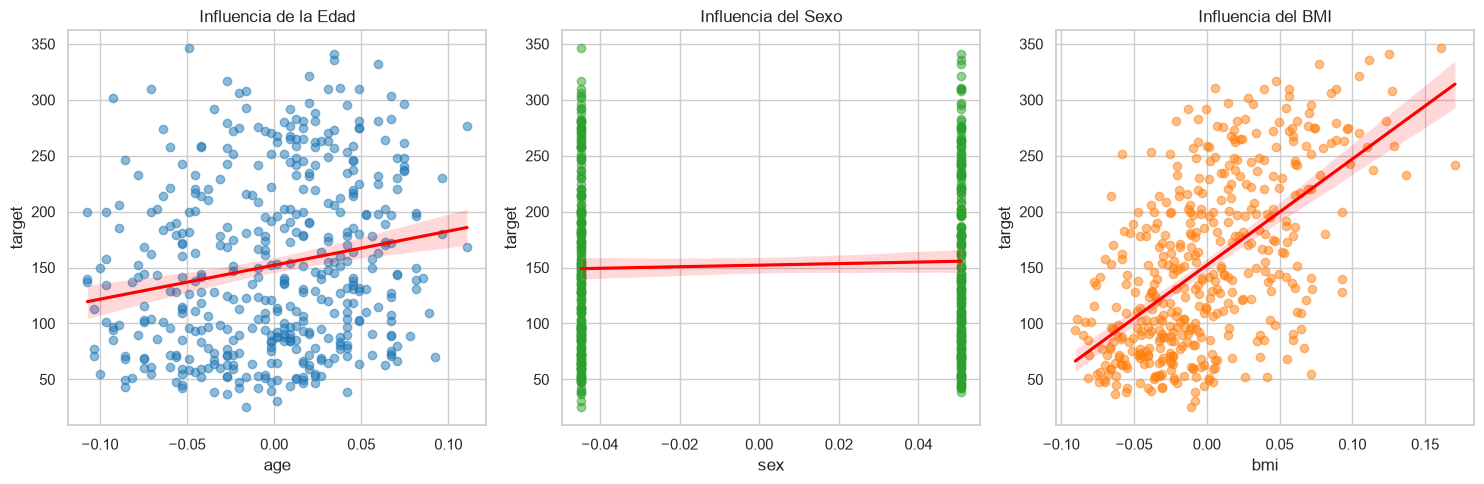


--- COEFICIENTES (ORDENADOS POR INFLUENCIA) ---
  Variable  Coeficiente_Original  Coeficiente_Estandarizado
4       s1           -931.488846                 -44.448856
8       s5            736.198859                  35.161195
2      bmi            542.428759                  25.607121
5       s2            518.062277                  24.640954
3       bp            347.703844                  16.828872
7       s4            275.317902                  13.138784
1      sex           -241.964362                 -11.511809
6       s3            163.419983                   7.676978
9       s6             48.670657                   2.351364
0      age             37.904021                   1.753758


In [20]:
# TODO: completa esta celda
# load_diabetes(as_frame=True) te devuelve .data y .target como objetos de pandas.
# Antes de decidir que variable influye mas, preguntate si estan todas en la misma escala.
import pandas as pd
import numpy as np
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load a new dataset

nwdt_set = datasets.load_diabetes()
df_nw = pd.DataFrame(data=nwdt_set.data, columns=nwdt_set.feature_names)

df_nw['target'] = nwdt_set.target

#print(nwdt_set)
print("HEAD:")
print(df_nw.head())
print("INFO:")
print(df_nw.info())
print("SHAPE:")
print(df_nw.shape)
print("DESCRIBE:")
print(df_nw.describe())

# 2. Adjust a multiple regression with at least 3 predictive variables

# Cambiamos X_simple para que coja TODAS las variables en lugar de solo 3
X_all = df_nw.drop(columns=['target'])
y_all = df_nw["target"]

# 80% de entrenamiento
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, random_state=42, test_size=0.2)

model = LinearRegression()
model.fit(X_train, y_train)


y_pred = model.predict(X_test)

# 3. Evaluate the model using R^2 and RMSE
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"\n--- RESULTADOS DATASET DIABETES ---")
print(f"RMSE: {rmse:.2f}")
print(f"R²: {r2:.4f}")

# 4. Interpreta que variable  

# Configurar el tamaño del gráfico
plt.figure(figsize=(15, 5))

# 1. Gráfico Edad vs Target
plt.subplot(1, 3, 1)
sns.regplot(data=df_nw, x='age', y='target', 
            scatter_kws={'alpha':0.5, 'color':'#1f77b4'}, 
            line_kws={'color':'red'})
plt.title('Influencia de la Edad')

# 2. Gráfico Sexo vs Target
plt.subplot(1, 3, 2)
sns.regplot(data=df_nw, x='sex', y='target', 
            scatter_kws={'alpha':0.5, 'color':'#2ca02c'}, 
            line_kws={'color':'red'})
plt.title('Influencia del Sexo')

# 3. Gráfico BMI vs Target
plt.subplot(1, 3, 3)
sns.regplot(data=df_nw, x='bmi', y='target', 
            scatter_kws={'alpha':0.5, 'color':'#ff7f0e'}, 
            line_kws={'color':'red'})
plt.title('Influencia del BMI')

# Ajustar los espacios y mostrar
plt.tight_layout()
plt.show()

# Standarize variables and compare 
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model_scaled = LinearRegression()
model_scaled.fit(X_train_scaled, y_train)

# --- AÑADIDO: TABLA DE COEFICIENTES (ORDENADOS POR INFLUENCIA) ---
coef_df = pd.DataFrame({
    'Variable': X_train.columns,
    'Coeficiente_Original': model.coef_,
    'Coeficiente_Estandarizado': model_scaled.coef_
})

# Calculamos el valor absoluto para ordenar por "peso" real, sin importar si es positivo o negativo
coef_df['influencia_absoluta'] = coef_df['Coeficiente_Estandarizado'].abs()

# Ordenamos de mayor a menor y quitamos la columna de apoyo
coef_df = coef_df.sort_values(by='influencia_absoluta', ascending=False).drop(columns=['influencia_absoluta'])

print("\n--- COEFICIENTES (ORDENADOS POR INFLUENCIA) ---")
print(coef_df)

### Mis reflexiones sobre el ejercicio 3
---

- Has ordenado las variables por el tamaño de su coeficiente. ¿En qué condiciones ese ranking significa "influencia" y en cuáles es engañoso? Comprueba si tu dataset cumple esas condiciones.

    - Si las variables no siguen un patrón de escalado de un ranking no tienen correlación. (NO COMPLETA)

    $y = \beta_0 + \beta_1x_1 + \beta_2x_2 + ... + \beta_nx_n$
    
    Los coeficientes cuanto más altos de valor afectan más al valor ya que se multiplica cada uno por su valor


- Has trabajado con dos datasets con R² muy distintos. ¿Cuál de los dos modelos dirías que es "mejor"? Cuidado con la pregunta.

    -  Ninguno es mejor solo que al comparar distintos datos no buscan lo mismo con lo que no son comparables.

- Si tuvieras que entregar uno de los modelos de esta sesión a alguien que lo va a usar sin ti delante, ¿qué escribirías en el README para que no lo use mal?

    - Pues que ejecute primero .head(), .info() y .decribe() para conocer como son los datos estructurados. Y el resultado del R^2, RMSE y MAE. Como se setean los valores de X e y. Explicación de que es cada variable (Importante que la persona entienda que es de lo que estamos hablando)
---